In [1]:
!pip install ortools
from ortools.linear_solver import pywraplp as OR
import time
import pandas as pd
import plotly.graph_objects as go

# Load the Manhattan street capacity graph dataset
file_path = r'C:\Users\DELL\Downloads\manhattan_street_capacities (1).csv'
df_manhattan_graph = pd.read_csv(file_path)
print(df_manhattan_graph.head())

   ---------------------------------------- 0.0/24.7 MB ? eta -:--:--
   ------ --------------------------------- 3.9/24.7 MB 25.8 MB/s eta 0:00:01
   -------------- ------------------------- 9.2/24.7 MB 27.5 MB/s eta 0:00:01
   -------------------------- ------------- 16.5/24.7 MB 27.7 MB/s eta 0:00:01
   ------------------------------------- -- 23.1/24.7 MB 28.5 MB/s eta 0:00:01
   ---------------------------------------  24.6/24.7 MB 25.5 MB/s eta 0:00:01
   ---------------------------------------- 24.7/24.7 MB 22.2 MB/s  0:00:01

   ------------- -------------------------- 1/3 [absl-py]
   ------------- -------------------------- 1/3 [absl-py]
   ------------- -------------------------- 1/3 [absl-py]
   -------------------------- ------------- 2/3 [ortools]
   -------------------------- ------------- 2/3 [ortools]
   -------------------------- ------------- 2/3 [ortools]
   -------------------------- ------------- 2/3 [ortools]
   -------------------------- ------------- 2/3 [ortoo

In [2]:
# Extract nodes, edges, and compute capacities
nodes = list(df_manhattan_graph['source_osm'].unique())

# Choose source to be the World Trade Center, and sink to be Hunter College
source, sink = 42453395, 42431678

edges = list(zip(df_manhattan_graph['source_osm'], df_manhattan_graph['target_osm']))

# capacity[i,j] is the capacity of edge (i,j)
capacity = df_manhattan_graph.groupby(['source_osm', 'target_osm'])['capacity'].sum().to_dict()

In [3]:
start_time = time.time()

m = OR.Solver('Max Flow', OR.Solver.GLOP_LINEAR_PROGRAMMING)

# Add flow variables f
f = {}
for (i, j) in edges:
    f[i, j] = m.NumVar(0, m.infinity(), 'f[{},{}]'.format(i, j))

# Add conservation of flow constraints for non-source/sink nodes
for i in nodes:
    if i not in (source, sink):
        m.Add(
            sum(f[j, x] for (j, x) in edges if x == i) - 
            sum(f[i, j] for (x, j) in edges if x == i) == 0
        )

# Add capacity constraints
for (i, j) in edges:
    m.Add(f[i, j] <= capacity[i, j])

# Add non-negativity constraints
for (i, j) in edges:
    m.Add(f[i, j] >= 0)

# Set Objective: Maximize flow into the sink
m.Maximize(sum(f[i, j] for (i, j) in edges if j == sink))

m.Solve()

end_time = time.time()
diff = time.gmtime(end_time - start_time)
print('\n[Total time used: {} minutes, {} seconds]'.format(diff.tm_min, diff.tm_sec))
print('Objective:', m.Objective().Value())


[Total time used: 0 minutes, 28 seconds]
Objective: 1200.0


In [4]:
flow_data = []
for (i, j) in edges:
    flow_data.append({
        'source_osm': i,
        'target_osm': j,
        'flow_result': f[i, j].solution_value()
    })

df_flows = pd.DataFrame(flow_data)

results_df = pd.merge(
    df_manhattan_graph,
    df_flows,
    on=['source_osm', 'target_osm'],
    how='left'
)

results_df['utilization'] = results_df['flow_result'] / results_df['flow_result'].max()

print(results_df.sort_values(by='utilization', ascending=False).head())

       source_osm  target_osm     street_name  capacity      u_lat      u_lon  \
9197   5706569898    42427316    Canal Street      3500  40.718449 -74.000552   
9271   6166413694    42449689  Unnamed Street      3500  40.745630 -73.973182   
409      42427316  5706569898    Canal Street      3500  40.718019 -73.999953   
410      42427316    42440810    Canal Street      3500  40.718019 -73.999953   
9876  13064844941  3574648569  Unnamed Street      3500  40.705864 -74.015053   

          v_lat      v_lon  flow_result  utilization  
9197  40.718019 -73.999953       3500.0          1.0  
9271  40.746326 -73.973652       3500.0          1.0  
409   40.718449 -74.000552       3500.0          1.0  
410   40.717554 -73.999309       3500.0          1.0  
9876  40.707186 -74.015731       3500.0          1.0  


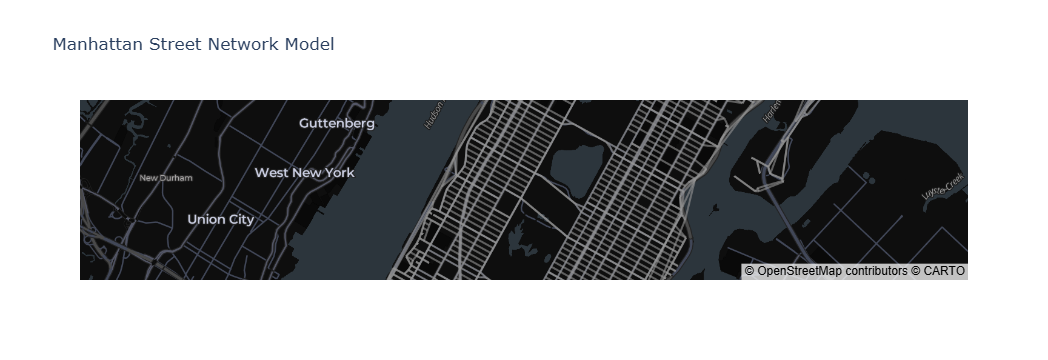

In [8]:
fig = go.Figure()

# Plot all street segments in a clean, uniform neutral color
lats = []
lons = []
for row in results_df.itertuples():
    lats.extend([row.u_lat, row.v_lat, None])
    lons.extend([row.u_lon, row.v_lon, None])

fig.add_trace(go.Scattermap(
    lat=lats,
    lon=lons,
    mode='lines',
    line=dict(width=2, color='rgba(150, 150, 150, 0.6)'), # Neutral gray lines
    name='Manhattan Streets',
    hoverinfo='none'
))

fig.update_layout(
    map=dict(
        style="carto-darkmatter",
        center=dict(lat=40.7831, lon=-73.9712), # Centered on Manhattan
        zoom=12
    ),
    title="Manhattan Street Network Model",
    showlegend=False
)

# Render the clean map directly inside the notebook without endpoints
fig.show()